# Chapitre 2 - Cours 1 : moindres carrés et plus proches voisins

Ce notebook couvre les sections 2.1 à 2.3 du livre. Nous y présentons les deux méthodes
de prédiction les plus simples :

- le **modèle linéaire** ajusté par moindres carrés : très structuré, stable, mais
  reposant sur une hypothèse forte (la linéarité) ;
- les **$k$ plus proches voisins** : presque aucune hypothèse, très flexible, mais
  instable.

Nous les comparons sur la simulation « mixture » du livre (figures 2.1 à 2.5), et nous
rencontrons pour la première fois le **classifieur de Bayes**, la règle optimale.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch02_supervise as c2

set_style()
rng = np.random.RandomState(0)

## 1. Notations (section 2.2)

- Une **variable d'entrée** est notée $X$ ; si c'est un vecteur, ses composantes sont
  $X_j$, $j = 1, \dots, p$.
- Une sortie quantitative est notée $Y$, une sortie qualitative $G$ (à valeurs dans un
  ensemble fini $\mathcal G$).
- Les **majuscules** désignent les variables aléatoires « génériques » ; les
  **minuscules** leurs valeurs observées : la $i$-ème observation de $X$ est $x_i$
  (un vecteur colonne de $\mathbb R^p$).
- Les **matrices** sont en gras : $\mathbf X$ est la matrice $N \times p$ dont la
  $i$-ème ligne est $x_i^T$. Le vecteur de toutes les observations de la variable $X_j$
  est noté $\mathbf x_j$ (une colonne de $\mathbf X$, de taille $N$).

L'apprentissage supervisé consiste, étant donné $X$, à fournir une bonne prédiction
$\hat Y$ de $Y$ (ou $\hat G$ de $G$), à partir de l'échantillon d'apprentissage
$\{(x_i, y_i)\}_{i=1}^N$.

Les classes qualitatives sont souvent **codées numériquement**. Pour deux classes, on
utilise $0/1$ (ou $-1/+1$). Pour $K$ classes, on utilise des **variables indicatrices**
(*dummy variables*) : un vecteur $(Y_1, \dots, Y_K)$ de $K$ bits dont un seul vaut 1.

## 2. Le modèle linéaire et les moindres carrés (section 2.3.1)

Étant donné un vecteur d'entrée $X^T = (X_1, \dots, X_p)$, on prédit $Y$ par
$$\hat Y = \hat\beta_0 + \sum_{j=1}^p X_j \hat\beta_j \qquad \text{(éq. (2.1) du livre)}.$$
Le terme $\hat\beta_0$ est l'**ordonnée à l'origine** (le *biais* en apprentissage
automatique). En ajoutant une composante constante égale à 1 au vecteur $X$, on écrit
de façon compacte $\hat Y = X^T\hat\beta$ (éq. (2.2)).

Pour choisir $\beta$, la méthode des **moindres carrés** minimise la somme des carrés
des résidus
$$\mathrm{RSS}(\beta) = \sum_{i=1}^N (y_i - x_i^T\beta)^2 = (\mathbf y - \mathbf X\beta)^T(\mathbf y - \mathbf X\beta)
\qquad \text{(éq. (2.3)-(2.4))}.$$
C'est une fonction quadratique de $\beta$ ; cherchons où son gradient s'annule.

**Calcul du gradient.** On développe :
$$\mathrm{RSS}(\beta) = \mathbf y^T\mathbf y - 2\beta^T\mathbf X^T\mathbf y + \beta^T\mathbf X^T\mathbf X\beta,$$
car $\mathbf y^T\mathbf X\beta$ est un réel, égal à sa transposée $\beta^T\mathbf X^T\mathbf y$.
On utilise les règles de dérivation $\nabla_\beta(\beta^T a) = a$ et
$\nabla_\beta(\beta^T A\beta) = 2A\beta$ pour $A$ symétrique :
$$\nabla \mathrm{RSS}(\beta) = -2\mathbf X^T\mathbf y + 2\mathbf X^T\mathbf X\beta.$$

Annuler le gradient donne les **équations normales**
$$\mathbf X^T(\mathbf y - \mathbf X\beta) = 0 \qquad \text{(éq. (2.5))}.$$
Si $\mathbf X^T\mathbf X$ est inversible (colonnes de $\mathbf X$ linéairement
indépendantes), la solution est unique :
$$\hat\beta = (\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf y \qquad \text{(éq. (2.6))}.$$
C'est bien un minimum : la hessienne $2\mathbf X^T\mathbf X$ est symétrique positive
(car $v^T\mathbf X^T\mathbf X v = \|\mathbf Xv\|^2 \ge 0$), donc $\mathrm{RSS}$ est convexe.

> **Intuition.** Les équations normales disent que le vecteur des résidus
> $\mathbf y - \mathbf X\hat\beta$ est **orthogonal** à chaque colonne de $\mathbf X$ :
> $\mathbf X\hat\beta$ est la projection orthogonale de $\mathbf y$ sur l'espace engendré
> par les colonnes (chapitre 3).

**Utilisation en classification.** On code la classe par $Y = 0$ (BLEU) ou $Y = 1$
(ORANGE), on ajuste $\hat Y = x^T\hat\beta$ par moindres carrés, puis on classe :
$$\hat G(x) = \begin{cases} \text{ORANGE} & \text{si } x^T\hat\beta > 0{,}5,\\
\text{BLEU} & \text{si } x^T\hat\beta \le 0{,}5 \end{cases} \qquad \text{(éq. (2.7))}.$$
La **frontière de décision** $\{x : x^T\hat\beta = 0{,}5\}$ est une droite (un hyperplan
en dimension $p$).

### Les données « mixture »

Le livre utilise un échantillon simulé de $N = 200$ points de $\mathbb R^2$, 100 de
chaque classe. Nous chargeons les données exactes du livre.

In [2]:
mix = datasets.load_mixture_example()
X, g = mix["x"], mix["y"]
means = mix["means"]
print(X.shape, np.bincount(g))

(200, 2) [100 100]


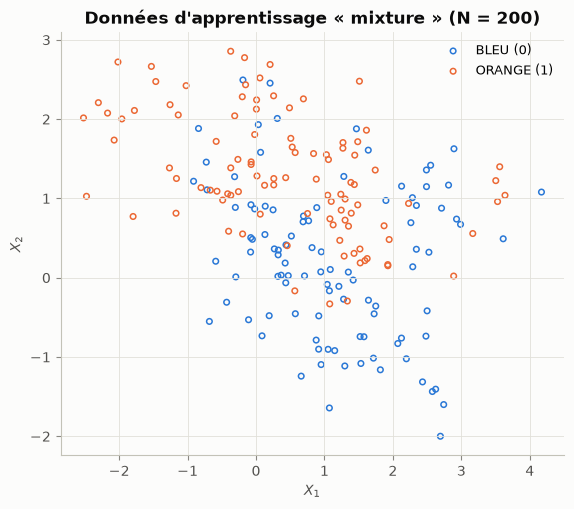

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for c, col, name in [(0, BLUE, "BLEU (0)"), (1, ORANGE, "ORANGE (1)")]:
    ax.scatter(X[g == c, 0], X[g == c, 1], s=16, facecolors="none", edgecolors=col,
               linewidths=1.1, label=name)
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_title("Données d'apprentissage « mixture » (N = 200)")
ax.legend()
plt.show()

Les deux classes se chevauchent largement : aucune règle ne pourra les séparer
parfaitement. Ajustons le modèle linéaire avec notre fonction `least_squares_fit`
(qui résout les équations normales).

In [4]:
beta = c2.linear_classifier_fit(X, g)
print("beta_hat =", np.round(beta, 4))
A = c2.add_intercept(X)
print("vérification (2.6) :", np.allclose(beta, np.linalg.solve(A.T @ A, A.T @ g)))
print("équations normales X^T(y - X beta) =", np.round(A.T @ (g - A @ beta), 10))

beta_hat = [ 0.3291 -0.0226  0.2496]
vérification (2.6) : True
équations normales X^T(y - X beta) = [-0. -0. -0.]


Préparons une grille fine du plan pour représenter les régions de décision.

In [5]:
xlim, ylim = (-2.6, 4.2), (-2.0, 2.9)
xx, yy, grid = decision_grid(xlim, ylim, n=250)
lin_score = c2.least_squares_predict(grid, beta).reshape(xx.shape)

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
c2.plot_two_class(ax, X, g, xx, yy, lin_score, title="Régression linéaire d'un codage 0/1 (figure 2.1)")
ax.legend(loc="upper left")
plt.show()